# Parte 1 — O primeiro modelo em produção

**Banco Aurora · Prevenção a Fraudes** · entrega: **11/11/2026, 23h59 (Brasília)**

**Autora: Mayumi Castiglioni.** Notebook da atividade atualizado em 10/11/2026. A análise de dados e a comparação de cinco hipóteses estão em `notebooks/01_analise_e_escolha.ipynb`; as células seguintes consolidam as decisões e verificações de produção, monitoramento e entrega. Leia `docs/conceitos-e-pegadinhas.md` antes de reproduzir.

## 0. Ambiente

Rode a célula abaixo. Se algo aparecer como `FALHOU`, resolva antes de seguir: o resto do notebook depende das quatro conexões.

In [1]:
# CÉLULA PRONTA — só rode. Tudo precisa aparecer como "ok".
import json
import urllib.request

import mlflow
import psycopg2

import config

for nome, uri in [("Postgres / antifraude", config.URI_BANCO_APP), ("Postgres / mlflow", config.URI_BANCO_MLFLOW)]:
    try:
        psycopg2.connect(uri).close()
        print(f"{nome:24} ok")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

for nome, url in [("MLflow", f"{config.MLFLOW_TRACKING_URI}/health"), ("Sistema", f"{config.SISTEMA_URL}/saude")]:
    try:
        resp = urllib.request.urlopen(url, timeout=5).read().decode()
        print(f"{nome:24} ok -> {resp[:160]}")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
print("\ntracking uri:", mlflow.get_tracking_uri())

Postgres / antifraude    ok
Postgres / mlflow        ok
MLflow                   ok -> OK
Sistema                  ok -> {"sistema":"ok","contrato":"1.0","modelo":{"ok":true,"versao":"1","threshold":0.1,"run_id":"ff48c43154624ec9a1e3d16688909ef3","descricao":"RandomForestClassifie

tracking uri: http://127.0.0.1:5001


## 1. O contrato

O contrato (`contrato/contrato_features.yaml`) é o acordo com o time de Plataforma: as 13 features que o sistema de produção entrega, com tipo, regra de cálculo e valores permitidos. **O sistema rejeita qualquer lote que não o respeite**, e o seu modelo vai receber exatamente isso — nada mais.

**Faça**
1. Leia o YAML com `yaml.safe_load` e monte, a partir dele (não digitando à mão), a lista das features na ordem do contrato, separando categóricas e numéricas.
2. Carregue `dados/transacoes_semanas_01_12.csv` e `dados/rotulos_semanas_01_12.csv` e junte os dois pela `id_transacao`. Garanta que a junção é 1 para 1 e que nenhuma linha se perdeu.
3. Escreva uma validação do histórico contra o contrato: colunas presentes, tipos, valores fora da lista nas categóricas, valores fora de `min`/`max`, nulos. O histórico passa?

> Por que validar um dado que "veio do próprio banco"? Porque o modelo vai aprender o que estiver aqui. Se o treino tiver algo que a produção não terá (ou o contrário), o erro só aparece depois, em produção.

# Auditoria inicial executada em 06/11/2026

Reprodução: `python scripts/auditar_historico.py <caminho-do-zip>`. Dependências locais: pandas, numpy e PyYAML. Evidências completas e hashes dos CSVs estão em auditoria-inicial.json. Nenhum dado foi alterado.

- 240.384 transações e 240.384 rótulos, sem IDs duplicados; junção 1:1 sem perdas ou sobras.
- Nenhuma violação encontrada nas verificações de nulos, categorias, finitude, inteiros, booleanos e limites das 13 features.
- Datas de transação válidas e coerentes com hora e dia da semana.
- Razão valor/média compatível com arredondamento de quatro casas: erro máximo aproximadamente 0,00005; nenhuma linha fora de tolerância absoluta de 0,000051. Isso não demonstra a disponibilidade temporal correta das médias upstream.
- Todos os rótulos são binários. data_contestacao está ausente em 236.886 registros, todos de classe 0; nenhuma fraude sem essa data. Não excluir legítimos por essa ausência. A maturidade dos lotes futuros ainda precisa ser tratada separadamente.

| Semana | Custo de aprovar tudo | Custo da regra Pix > R$ 1.000 |
|---|---|---|
| 11 | R$ 177.029,27 | R$ 102.820,44 |
| 12 | R$ 199.006,26 | R$ 122.529,35 |

Resultados preliminares: não provam ausência de vazamento na construção das features, nem confirmam a semântica de todos os cálculos históricos. Nenhum modelo treinado. Auditar intervalos temporais de rótulos, consistência das semanas e disponibilidade das features antes de declarar auditoria completa.

Estes resultados devem ser resumidos na seção 1 do notebook e copiados para a documentação exportada na entrega.

## Complemento temporal

O arquivo auditoria-temporal.json registra 200.887 linhas em treino e 39.497 em validação. As semanas são consecutivas, de 01/06/2026 a 23/08/2026, sem sobreposição dos intervalos semanais observados. Nenhuma contestação de fraude inválida ou anterior à transação; atrasos observados entre aproximadamente zero e sete dias. Isso não implica que o lote esteja completo antes do encerramento definido pelo negócio.

Há 22.674 clientes presentes em treino e validação. Repetição de cliente é compatível com prever transações futuras da base existente; não substituímos o corte temporal exigido por uma divisão por cliente. id_cliente permanece fora das features. Generalização para clientes inéditos é uma questão distinta, não demonstrada por esse resultado.

Não foram identificadas razões para excluir ou imputar linhas nas verificações executadas. A disponibilidade histórica de médias, contagens e distâncias não pode ser reconstruída apenas com este pacote: usar as features fornecidas segundo o contrato e declarar a limitação, sem afirmar ausência comprovada de vazamento upstream.


In [2]:
import json
from pathlib import Path
auditoria = json.loads(Path('docs/evidencias/auditoria-inicial.json').read_text(encoding='utf-8'))
print(auditoria['juncao'])

{'both': 240384, 'left_only': 0, 'right_only': 0}


## 2. Divisão temporal

A regra combinada com o negócio: **treino nas semanas 1 a 10, validação nas semanas 11 e 12**.

**Faça**
1. Separe os dois conjuntos pela coluna `semana`.
2. Mostre a taxa de fraude por semana e o tamanho de cada conjunto.
3. Responda em uma célula de texto: por que uma divisão aleatória (`train_test_split`) seria um erro aqui?

**Resposta — divisão temporal**

O treino usa 200.887 transações das semanas 1–10 e a validação usa 39.497 das semanas 11–12. A divisão aleatória misturaria períodos anteriores e futuros, contrariando a avaliação operacional pedida e permitindo que padrões futuros influenciassem o treino. Os IDs e demais metadados não entram no modelo: somente as 13 features do contrato. A taxa de fraude muda entre semanas, então as métricas e os custos também são apresentados por semana. A auditoria e os hashes estão em `docs/evidencias/auditoria-inicial.json` e `auditoria-temporal.json`.

## 3. Pré-processamento em `features.py`

Escreva no arquivo `features.py` (não no notebook) o que transforma as 13 features cruas na entrada do seu algoritmo. Depois, importe aqui.

**Requisitos**
- O pré-processamento precisa ser parte do modelo que você registra (um `Pipeline` do scikit-learn). Em produção, o sistema entrega as features cruas e chama `predict_proba` — ele não transforma nada.
- As listas de colunas e de categorias vêm **do contrato**, não do que apareceu no treino. Pense no que acontece se uma UF que não está no treino aparecer em produção.
- Se o seu pipeline usar classes ou funções suas, o modelo precisa ser registrado com `code_paths=["features.py"]`.

> Dica: depois de editar o `features.py`, use `importlib.reload(features)` ou reinicie o kernel.

In [3]:
from features import construir, carregar_contrato
contrato = carregar_contrato()
print([f['nome'] for f in contrato['features']])

['valor_transacao', 'hora_transacao', 'dia_semana', 'canal', 'dispositivo_novo', 'qtd_transacoes_1h', 'valor_medio_30d', 'razao_valor_media', 'distancia_ultima_transacao_km', 'idade_conta_dias', 'destinatario_novo', 'categoria_estabelecimento', 'uf_cliente']


## 4. Pelo menos dois modelos, tudo no MLflow

Treine **pelo menos dois algoritmos** diferentes, cada um em uma run do MLflow.

**Faça**
1. Crie (ou use) um experimento com nome que você reconheça depois.
2. Em cada run, registre:
   - **parâmetros**: algoritmo, hiperparâmetros relevantes, semanas de treino e de validação, versão do contrato;
   - **métricas na validação**: PR-AUC, recall, precision e **custo** (seção 5);
   - **o modelo** (`mlflow.sklearn.log_model`), com assinatura (`infer_signature`) e um `input_example`.
3. Compare as runs na interface do MLflow.

> Use PR-AUC e não ROC-AUC para comparar ranking: com 1,5% de fraude, a ROC-AUC fica alta até para modelos ruins.

# Protocolo e registro de experimentos

Data: 06/11/2026. Protocolo definido antes do treino; nenhum resultado de modelo disponível.

## Por que ampliar

Comparar famílias com hipóteses diferentes, além do mínimo de dois algoritmos, para justificar a escolha por evidências. Quantidade não é objetivo: executar primeiro uma configuração por família, registrar inclusive falhas e descartes e evitar busca extensa na validação.

## Hipóteses iniciais

| ID | Família | Hipótese antes do teste | Limitação a observar |
|---|---|---|---|
| E01 | Regressão logística | Uma relação aditiva pode oferecer referência simples, rápida e interpretável | Pode perder interações; precisa de escala e codificação adequadas |
| E02 | Árvore de decisão com profundidade limitada | Regras não lineares simples podem reduzir custo e facilitar explicação | Instabilidade e probabilidades grosseiras em folhas pequenas |
| E03 | Random Forest | Agregar árvores pode capturar interações com menor variância que árvore única | Custo computacional e scores que exigem avaliação do corte |
| E04 | Extra Trees | Maior aleatoriedade nos cortes pode melhorar generalização e tempo comparada à floresta | Pode aumentar viés; não presumir superioridade |
| E05 | HistGradientBoostingClassifier | Boosting pode capturar relações não lineares complementares e corrigir erros sucessivos | Conferir codificação, categorias, memória e estabilidade; não assumir suporte automático |

A escolha destas famílias é uma decisão de protocolo; a vencedora continua aberta. Não adicionar bibliotecas externas (XGBoost, LightGBM, CatBoost) apenas para ampliar a lista. Sua inclusão futura exige hipótese distinta, compatibilidade e registro anterior à execução.

## Condições comparáveis

- Entrada sempre com as 13 features cruas, em Pipeline. Categorias e ordem derivadas do contrato.
- Treino 1–10; seleção 11–12, sem ajuste de transformações no período de validação. Semente 42 quando aplicável.
- Uma configuração inicial por família. Definir e registrar hiperparâmetros antes de executar. Sem pesos de classe, reamostragem ou calibração implícitos: qualquer variante é novo experimento com justificativa.
- Transformações podem diferir conforme algoritmo, mas devem estar registradas e ser compatíveis com produção. Comparar tempo de treino e inferência, além de resultado.
- Otimizar corte global em grade 0,01–0,99 com passo 0,01. Registrar regra de desempate antes da execução (proposta: menor taxa de bloqueio entre custos iguais).
- Métrica primária: soma dos valores de fraudes aprovadas + R$ 15 por legítima bloqueada. Identificar PR-AUC como average precision caso essa implementação seja adotada.
- Reportar total e semanas 11 e 12 separadas. Comparar aprovar tudo, regra Pix > R$ 1.000 e o mesmo modelo a 0,5.
- Resultados são validação usada na escolha; quanto mais tentativas, maior o risco de seleção otimista. Não chamar de teste independente. Variantes adicionais precisam de justificativa e orçamento explícito.

## Registro obrigatório de cada tentativa

Antes: ID, hipótese, família, configuração, pré-processamento, semente, período e versão do contrato. Depois: status (concluído/falhou/descartado), run_id, commit, duração, custo, corte, precision, recall, average precision, bloqueios legítimos, fraude monetária perdida e conclusão.

Registrar erros e descartes sem inventar métricas. Uma tentativa falha não equivale a evidência de baixa qualidade preditiva. Não apagar runs desfavoráveis. Diferenciar execução repetida por erro técnico de hipótese nova.

## Como isso entra na entrega

O professor recebe o notebook e o ZIP exportado, não necessariamente o repositório. Portanto:

1. Seção 4 do notebook: tabela de hipóteses ANTES dos resultados, configurações e run_ids de todas as tentativas.
2. Seção 5: resultados e baselines, curvas custo × corte e análise por semana.
3. Seção 6: comparação final, motivos de escolha/descarte, limitações e efeito da seleção na validação.
4. Cada tentativa tem sua run no MLflow. Arquivar também tabela consolidada e relatório de experimentos na run campeã, dentro de referencia/experimentos/, pois a célula original exporta essa pasta. Não confundir esses documentos com o dataset de referência.
5. Conferir o ZIP: a célula original não exporta automaticamente docs/ nem todas as runs. Incluir uma cópia dos documentos de decisões e pegadinhas em referencia/documentacao/ e um resumo suficiente das runs concorrentes antes de gerar a entrega.
6. Abrir o notebook salvo e inspecionar o ZIP final. Nenhuma hipótese deve aparecer só no GitHub e faltar na entrega.

## Registro atual

| ID | Status | Resultado / motivo |
|---|---|---|
| E01–E05 | Planejados | Aguardam auditoria completa, ambiente e configurações registradas |

## Configurações congeladas antes da rodada

E01: LogisticRegression(max_iter=1000, random_state=42), escala numérica. E02: DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42). E03: RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20, n_jobs=2, random_state=42). E04: ExtraTreesClassifier com os mesmos parâmetros de capacidade da floresta. E05: HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, l2_regularization=1, random_state=42). Demais parâmetros são padrões da versão e serão registrados na run.

Todas usam OneHotEncoder com categorias do contrato e saída densa; apenas E01 escala numéricas. Pesos de classe permanecem padrão, sem reamostragem ou calibração. Empates em custo arredondado a centavos: menor taxa de bloqueio, depois menor corte. Se houver empate final entre modelos, considerar estabilidade semanal e simplicidade, registrando a justificativa.

Ambiente: Python 3.11, sklearn 1.8.0, cliente/servidor MLflow 2.19.0 em instância local separada (porta 5001; backend aurora_mlflow). O ambiente curto herda pacotes locais para reduzir instalação; registrar versões efetivas e não chamar isso de ambiente hermético.


In [4]:
# Rodada já executada; este bloco consulta evidências, sem retreinar.
# Reprodução completa: python scripts/executar_experimentos.py
import json, pandas as pd
from pathlib import Path
registros = json.loads(Path('docs/evidencias/experimentos-iniciais.json').read_text(encoding='utf-8'))
display(pd.DataFrame([dict(id=r['id'], algoritmo=r.get('algoritmo'), status=r['status'], run_id=r['run_id'], **r.get('resultado',{})) for r in registros]))

,id,algoritmo,status,run_id,threshold,custo,recall,precision,average_precision,legitimas_bloqueadas,fraude_perdida,taxa_bloqueio
0,E01,LogisticRegression,concluido,c15eb3a19dd140848563c236fa561f82,0.06,37608.05,0.751667,0.329920,0.672617,916,23868.05,0.034610
1,E02,DecisionTreeClassifier,concluido,dda48eedb4c74379b3d32e7cf342db5c,0.03,32578.35,0.858333,0.311555,0.755200,1138,15508.35,0.041851
2,E03,RandomForestClassifier,concluido,ff48c43154624ec9a1e3d16688909ef3,0.10,18985.61,0.831667,0.509704,0.813039,480,11785.61,0.024787
3,E04,ExtraTreesClassifier,concluido,9466c1b470ef444d8ba44a51ba28e397,0.06,29196.24,0.825000,0.338115,0.693190,969,14661.24,0.037066
4,E05,HistGradientBoostingClassifier,concluido,0512c9f8a4ac4307b0a25efc406fd812,0.06,24587.99,0.840000,0.519588,0.832029,466,17597.99,0.024559


## 5. Threshold pelo custo

O `predict_proba` devolve um score. O **threshold** é o corte: `score >= threshold` → bloquear. O padrão de 0,5 não tem nada a ver com o problema do banco.

**Custo de um conjunto de decisões** = soma do **valor** das fraudes aprovadas + **R$ 15** × legítimas bloqueadas.

**Faça**
1. Escreva a função de custo (ela vai para o `monitoramento.py` na seção 9; pode começar aqui).
2. Para cada modelo, varra thresholds de 0,01 a 0,99 na **validação** e escolha o de menor custo. Faça o gráfico custo × threshold.
3. No threshold escolhido, mostre recall, precision e custo. Registre o threshold e o custo como métricas da run.
4. Mostre a comparação com o **piso** pedido pelo negócio:
   - aprovar tudo;
   - a regra atual: bloquear todo Pix acima de R$ 1.000;
   - o próprio modelo com threshold 0,5.

# Comparação inicial e escolha fundamentada

Rodada executada em 06/11/2026, configurações definidas previamente em docs/experimentos.md.

| ID | Algoritmo | Corte | Custo 11–12 (R$) | Recall | Precision | Average precision |
|---|---|---|---|---|---|---|
| E01 | LogisticRegression | 0.06 | 37608.05 | 0.7517 | 0.3299 | 0.6726 |
| E02 | DecisionTreeClassifier | 0.03 | 32578.35 | 0.8583 | 0.3116 | 0.7552 |
| E03 | RandomForestClassifier | 0.10 | 18985.61 | 0.8317 | 0.5097 | 0.8130 |
| E04 | ExtraTreesClassifier | 0.06 | 29196.24 | 0.8250 | 0.3381 | 0.6932 |
| E05 | HistGradientBoostingClassifier | 0.06 | 24587.99 | 0.8400 | 0.5196 | 0.8320 |

## Escolha

Escolha posteriormente aprovada e promovida: E03 (RandomForestClassifier), corte 0,10. Custo de R$ 18.985,61 nas semanas 11–12; economia de R$ 206.364,18 (91,58%) contra a regra Pix > R$ 1.000. Foram bloqueadas 480 transações legítimas, afetando 476 clientes distintos (dois em ambas as semanas), e passaram R$ 11.785,61 em fraude. A escolha e o corte usam a validação; não são teste independente. A promoção consta no registro 009.

- Semana 11: custo R$ 11019.25; 267 legítimas bloqueadas; fraude perdida R$ 7014.25.
- Semana 12: custo R$ 7966.36; 213 legítimas bloqueadas; fraude perdida R$ 4771.36.

## Baselines agregados do selecionado

- aprovar_tudo: R$ 376035.53.
- regra_pix: R$ 225349.79.
- modelo_05: R$ 99338.94.

## Tentativas e descartes

- E01: não selecionado nesta rodada: custo superior ao escolhido; run `c15eb3a19dd140848563c236fa561f82`; treino 1.43s; inferência de 39.497 transações 0.069s.
- E02: não selecionado nesta rodada: custo superior ao escolhido; run `dda48eedb4c74379b3d32e7cf342db5c`; treino 3.34s; inferência de 39.497 transações 0.061s.
- E03: selecionado pelo menor custo; run `ff48c43154624ec9a1e3d16688909ef3`; treino 65.84s; inferência de 39.497 transações 0.361s.
- E04: não selecionado nesta rodada: custo superior ao escolhido; run `9466c1b470ef444d8ba44a51ba28e397`; treino 27.62s; inferência de 39.497 transações 0.535s.
- E05: não selecionado nesta rodada: custo superior ao escolhido; run `0512c9f8a4ac4307b0a25efc406fd812`; treino 12.11s; inferência de 39.497 transações 0.310s.

Tentativa técnica anterior E01: falha antes do treino por URI de artefatos e codificação do console; registro preservado em tentativa-tecnica-inicial.json. Não é evidência contra o algoritmo.

## Limitações

A seleção e o corte usam as mesmas semanas 11–12: são validação, não teste independente nem garantia futura. E03 foi promovida a `antifraude@champion` v1 após aprovação; monitoramento baseline, registro de versão, paridade da API e pacote final estão concluídos e documentados nas seções seguintes. O threshold global é uma simplificação exigida; o custo varia com o valor das transações.

![Curvas de custo](docs/evidencias/custo-por-threshold.png)


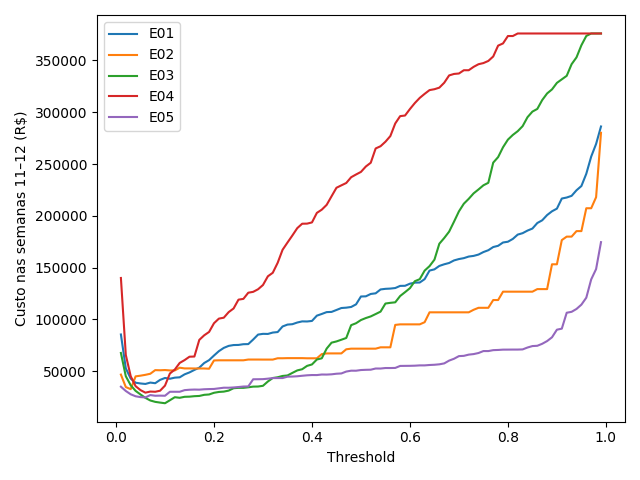

In [5]:
from IPython.display import display, Image
display(Image(filename='docs/evidencias/custo-por-threshold.png'))

## 6. A escolha

Em uma célula de texto, escolha o modelo que vai para produção e justifique **em linguagem de custo**, como você explicaria para a Helena: quanto ele custa por semana na validação, quanto economiza em relação à regra atual, quantos clientes legítimos ele incomoda e quanta fraude ainda passa.

Não vale "porque teve a maior PR-AUC". Vale usar a PR-AUC como argumento de apoio.


## Interpretação e sensibilidade

O boosting E05 teve maior average precision (0,8320 versus 0,8130), mas custo maior (R$ 24.587,99 versus R$ 18.985,61). Seu valor de fraude aprovada foi R$ 17.597,99, contra R$ 11.785,61 da floresta; apesar de bloquear 14 legítimas a menos, essa economia de R$ 210 não compensou a perda monetária adicional. Não escolher pela métrica de ranking isolada.

A Random Forest também teve custo inferior aos demais em cada uma das semanas, sem depender de compensar um resultado ruim em uma semana pelo outro. Isso é evidência observada, não teste estatístico de superioridade futura.

Cortes próximos do selecionado, sem novas configurações treinadas:

|   threshold |   custo |   recall |   precision |   average_precision |   legitimas_bloqueadas |   fraude_perdida |   taxa_bloqueio |
|------------:|--------:|---------:|------------:|--------------------:|-----------------------:|-----------------:|----------------:|
|        0.07 | 21639.8 | 0.858333 |    0.397377 |            0.813039 |                    781 |          9924.75 |       0.0328126 |
|        0.08 | 20316.6 | 0.845    |    0.437446 |            0.813039 |                    652 |         10536.6  |       0.029344  |
|        0.09 | 19604.9 | 0.835    |    0.482659 |            0.813039 |                    537 |         11549.9  |       0.0262805 |
|        0.1  | 18985.6 | 0.831667 |    0.509704 |            0.813039 |                    480 |         11785.6  |       0.0247867 |
|        0.11 | 21875.7 | 0.821667 |    0.530108 |            0.813039 |                    437 |         15320.7  |       0.0235461 |
|        0.12 | 24794.9 | 0.811667 |    0.558486 |            0.813039 |                    385 |         19019.9  |       0.0220776 |
|        0.13 | 24239.9 | 0.811667 |    0.583234 |            0.813039 |                    348 |         19019.9  |       0.0211408 |


In [6]:
# Clientes legítimos afetados: usar id_cliente apenas para relatório, nunca como feature.
from pathlib import Path
import pandas as pd
from IPython.display import display

ref_opcoes = [Path('dados/referencia_e03_semanas_11_12.csv'), Path('artefatos/referencia_e03_semanas_11_12.csv')]
ref_path = next(p for p in ref_opcoes if p.exists())
ref_clientes = pd.read_csv(ref_path, sep=';', dtype={'id_transacao': str})
ids_clientes = pd.read_csv('dados/transacoes_semanas_01_12.csv', usecols=['id_transacao','id_cliente'], dtype={'id_transacao':str,'id_cliente':str})
impacto = ref_clientes.merge(ids_clientes, on='id_transacao', how='left', validate='one_to_one')
assert impacto.id_cliente.notna().all() and len(impacto) == 39497
legitimas_bloqueadas = impacto[(impacto['fraude'] == 0) & (impacto['score'] >= 0.10)]
clientes_afetados = int(legitimas_bloqueadas.id_cliente.nunique())
por_semana_clientes = legitimas_bloqueadas.groupby('semana').agg(
    transacoes_legitimas_bloqueadas=('id_transacao','size'),
    clientes_distintos=('id_cliente','nunique')
).reset_index()
assert len(legitimas_bloqueadas) == 480 and clientes_afetados == 476
display(por_semana_clientes)
print(f"Total nas semanas 11–12: {len(legitimas_bloqueadas)} transações legítimas bloqueadas; {clientes_afetados} clientes distintos afetados.")
print('Dois clientes aparecem nas duas semanas; a soma das contagens semanais não é a contagem única do período.')

,semana,transacoes_legitimas_bloqueadas,clientes_distintos
0,11,267,266
1,12,213,212


Total nas semanas 11–12: 480 transações legítimas bloqueadas; 476 clientes distintos afetados.
Dois clientes aparecem nas duas semanas; a soma das contagens semanais não é a contagem única do período.


**Justificativa para a Helena:** recomendamos a Random Forest E03 com score ≥ 0,10 para encaminhar uma transação à verificação. O custo observado foi R$ 9.492,81 por semana nas duas semanas de validação, uma redução de 91,58% contra a regra atual de Pix acima de R$ 1.000. Foram bloqueadas 480 transações legítimas, afetando 476 clientes distintos (dois aparecem em ambas as semanas), a R$ 15 por transação; ainda passaram R$ 11.785,61 em fraude. O corte 0,5 custaria R$ 99.338,94. A comparação é retrospectiva nas semanas usadas para escolha; os resultados futuros precisam ser acompanhados pelo monitoramento.

## 7. Registro e promoção

**Faça**
1. Registre o modelo escolhido no Model Registry com o nome **`antifraude`** (é o nome que o sistema procura).
2. Na **versão** registrada (não na run), grave as tags:
   - `threshold` — o corte escolhido na seção 5 (o sistema lê daqui);
   - `motivo` — uma frase curta, ex.: `v1.0.0 - primeiro modelo em produção` (aparece no histórico de trocas do sistema).
3. Escreva uma **descrição** para a versão: algoritmo, threshold e por que foi escolhido.
4. Aponte o alias **`champion`** para essa versão.

Use o `MlflowClient` para os passos 2 a 4.

**Concluído em 10/11/2026 após aprovação da usuária.** `antifraude` v1 foi registrada a partir da run E03 `ff48c43154624ec9a1e3d16688909ef3`. A tag de versão `threshold=0.1`, o motivo e a descrição estão gravados; `champion` aponta para v1. A promoção e a paridade das probabilidades sobre a semana 12 foram verificadas antes de mover o alias. Evidência: `docs/evidencias/promocao-e03.json`.

In [7]:
import json
import mlflow
import config
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
cliente = MlflowClient()
champion = cliente.get_model_version_by_alias('antifraude', 'champion')
resultado_champion = {
    'nome': champion.name, 'versao': champion.version, 'run_id': champion.run_id,
    'threshold': champion.tags.get('threshold'), 'motivo': champion.tags.get('motivo'),
    'descricao': champion.description,
}
assert str(champion.version) == '1'
assert float(champion.tags['threshold']) == 0.10
assert champion.run_id == 'ff48c43154624ec9a1e3d16688909ef3'
print(json.dumps(resultado_champion, ensure_ascii=False, indent=2))

{
  "nome": "antifraude",
  "versao": "1",
  "run_id": "ff48c43154624ec9a1e3d16688909ef3",
  "threshold": "0.1",
  "motivo": "v1.0.0 - menor custo validado entre cinco famílias; promoção aprovada pela usuária em 10/11/2026",
  "descricao": "RandomForestClassifier E03, RandomForest pipeline com pré-processamento do contrato v1.0. Threshold 0.10. Selecionado por menor custo nas semanas de validação 11-12: R$ 18.985,61 em duas semanas, contra R$ 225.349,79 da regra Pix > R$ 1.000. A validação foi usada na seleção; não é teste independente nem garantia de desempenho futuro."
}


In [8]:
artefatos_referencia = [a.path for a in cliente.list_artifacts(champion.run_id, 'referencia')]
assert any('referencia_e03_semanas_11_12.csv' in a for a in artefatos_referencia)
print('Referência registrada na run campeã:')
for artefato in artefatos_referencia:
    print(' -', artefato)

Referência registrada na run campeã:
 - referencia/documentacao
 - referencia/experimentos
 - referencia/notebook_reproduzivel
 - referencia/referencia-e03-preparada.json
 - referencia/referencia_e03_semanas_11_12.csv


## 8. O sistema está usando o seu modelo?

A API local usada nesta execução é `http://127.0.0.1:8001`. GET /api/modelo e o endpoint de saúde confirmaram antifraude v1, champion, run E03 e threshold 0,10; a resposta inclui o histórico de troca. A célula seguinte envia cinco linhas da semana 12 com apenas as 13 features do contrato, compara o endpoint com o modelo carregado do registry e verifica as decisões com base no score original. Evidência da execução: `docs/evidencias/paridade-api-e03.json`.

In [9]:
import json
import urllib.request
import pandas as pd
import mlflow.sklearn
from app.contrato import carregar as carregar_contrato, nomes_features, tipar

url_api = 'http://127.0.0.1:8001'
resposta_saude = json.loads(urllib.request.urlopen(url_api + '/saude', timeout=10).read().decode('utf-8'))
assert resposta_saude['modelo']['versao'] == str(champion.version)
assert float(resposta_saude['modelo']['threshold']) == 0.10
status_api = json.loads(urllib.request.urlopen(url_api + '/api/modelo', timeout=10).read().decode('utf-8'))
assert status_api['modelo']['versao'] == str(champion.version) and float(status_api['modelo']['threshold']) == 0.10
assert status_api['contrato'] == '1.0' and str(status_api['trocas'][-1]['versao_nova']) == str(champion.version)

dados = pd.read_csv('dados/transacoes_semanas_01_12.csv')
features = nomes_features(carregar_contrato())
amostra = dados.loc[dados['semana'] == 12, features].head(5).copy()
assert len(amostra) == 5
modelo = mlflow.sklearn.load_model(f'models:/antifraude/{champion.version}')
scores_locais = modelo.predict_proba(tipar(amostra, carregar_contrato()))[:, 1]
payload = json.loads(amostra.to_json(orient='records'))
req = urllib.request.Request(url_api + '/predict', data=json.dumps(payload).encode('utf-8'), headers={'Content-Type':'application/json'}, method='POST')
with urllib.request.urlopen(req, timeout=30) as r:
    previsoes_api = json.loads(r.read().decode('utf-8'))
assert len(previsoes_api) == 5
comparacao_api = pd.DataFrame([{
    'linha': i + 1, 'score_modelo': float(score), 'score_api': pred['score'],
    'bloquear_api': pred['bloquear'], 'threshold_api': pred['threshold'],
    'versao_api': pred['versao_modelo'],
} for i, (score, pred) in enumerate(zip(scores_locais, previsoes_api))])
assert all(abs(row.score_api - round(row.score_modelo, 6)) < 1e-12 for row in comparacao_api.itertuples())
assert all(row.bloquear_api == (row.score_modelo >= 0.10) for row in comparacao_api.itertuples())
assert (comparacao_api['versao_api'] == str(champion.version)).all()
display(comparacao_api)

,linha,score_modelo,score_api,bloquear_api,threshold_api,versao_api
0,1,0.142132,0.142132,True,0.1,1
1,2,0.787202,0.787202,True,0.1,1
2,3,0.008546,0.008546,False,0.1,1
3,4,0.040347,0.040347,False,0.1,1
4,5,0.189517,0.189517,True,0.1,1


In [10]:
print('Paridade confirmada: 5/5 scores coincidem após arredondamento a seis casas; versão 1 e corte 0,10; decisões iguais ao score original.')

Paridade confirmada: 5/5 scores coincidem após arredondamento a seis casas; versão 1 e corte 0,10; decisões iguais ao score original.


## 9. Monitoramento baseline

A partir de quarta-feira chegam as semanas novas, uma por vez, e os rótulos de cada semana chegam só uma semana depois. O seu monitoramento precisa estar pronto **antes**, para que você perceba problemas sem esperar o negócio reclamar.

### 9.1 Referência
A referência é a "foto" de como os dados e os scores eram quando o modelo foi aprovado: as features da **validação** (semanas 11 e 12), o score do modelo escolhido e o rótulo.
- Salve a referência em arquivo e registre-a como **artefato da run do modelo campeão**, na pasta `referencia/` (`mlflow.log_artifacts(..., artifact_path="referencia", run_id=...)`). Assim, trocou o modelo, trocou a referência.

### 9.2 `monitoramento.py`
Escreva funções reutilizáveis que recebam a referência e um lote e devolvam tabelas legíveis:
- **Drift das features contínuas e do score**: teste **KS**, reportando a **estatística D** e o p-valor.
- **Drift das categóricas e booleanas** (e da hora): qui-quadrado ou comparação de proporções.
- **Saída do modelo**: taxa de bloqueio e valor bloqueado.
- **Performance, para quando o rótulo chegar**: recall, precision, PR-AUC e custo — **globais e por segmento** (uma coluna à sua escolha, ex.: `canal`).

### 9.3 Relatório zero
Rode o monitoramento comparando a **semana 11 com a semana 12** (as duas são da validação, nada mudou de propósito entre elas).
- Olhe os p-valores e as estatísticas. Algum p-valor é minúsculo mesmo sem nenhuma mudança relevante? Por quê?
- Defina e **justifique por escrito** os seus limites de alerta (ex.: D > 0,1). Eles valem para as próximas partes.

> O que você vai receber a cada semana: o CSV de transações (que você envia em **Lotes** no sistema) e, a partir da segunda semana, o CSV de rótulos da semana anterior (em **Rótulos**). Os dados já pontuados ficam em `GET /api/semanas/{n}/dados.csv`, com o score e, quando houver, o rótulo. É daí que o seu monitoramento vai ler.

**Concluído.** A referência das semanas 11–12 (39.497 linhas, com 13 features, score e rótulo) foi registrada como artefato da run E03 e vinculada à versão promovida. O relatório zero compara semana 11 com semana 12, sem retreino. Funções reutilizáveis reportam KS (D e p-valor) para variáveis contínuas e score, variação de proporções para categorias/discretas, saída operacional e performance global e por canal. Rótulos ausentes permanecem desconhecidos; custo final só é declarado quando o fechamento e a cobertura completa são confirmados. Evidências: `docs/evidencias/relatorio-zero-semanas-11-12.json` e `docs/evidencias/referencia-e03-preparada.json`.

In [11]:
from scripts.gerar_relatorio_zero import gerar
import pandas as pd

relatorio_zero = gerar()
print(f"Relatório recalculado e salvo: docs/evidencias/relatorio-zero-semanas-11-12.json")
print(f"Semana de referência: {relatorio_zero['semana_referencia']} ({relatorio_zero['n_referencia']:,} linhas)")
print(f"Semana comparada: {relatorio_zero['semana_lote']} ({relatorio_zero['n_lote']:,} linhas)")
print(f"Rótulos fechados confirmados: {relatorio_zero['rotulos_fechados_confirmados']}")
print(f"Alertas por magnitude: {relatorio_zero['resumo']['n_alertas']}")

Relatório recalculado e salvo: docs/evidencias/relatorio-zero-semanas-11-12.json
Semana de referência: 11 (20,399 linhas)
Semana comparada: 12 (19,098 linhas)
Rótulos fechados confirmados: True
Alertas por magnitude: 0


In [12]:
tabela_ks = pd.DataFrame(relatorio_zero['continuas'])
display(tabela_ks[['feature','D','p_valor','n_referencia','n_lote']].sort_values('D', ascending=False))

,feature,D,p_valor,n_referencia,n_lote
5,idade_conta_dias,0.059378,1.130019e-30,20399,19098
6,score,0.009664,3.135912e-01,20399,19098
4,distancia_ultima_transacao_km,0.008460,4.777147e-01,20399,19098
3,razao_valor_media,0.008002,5.499612e-01,20399,19098
2,valor_medio_30d,0.005520,9.229411e-01,20399,19098
0,valor_transacao,0.005072,9.603717e-01,20399,19098
1,qtd_transacoes_1h,0.003560,9.996003e-01,20399,19098


In [13]:
tabela_tv = pd.DataFrame(relatorio_zero['categoricas'])
resumo_tv = tabela_tv.groupby('feature', as_index=False)['variacao_total'].max().sort_values('variacao_total', ascending=False)
display(resumo_tv.head(10))

,feature,variacao_total
6,uf_cliente,0.021484
5,hora_transacao,0.017850
1,categoria_estabelecimento,0.014245
3,dia_semana,0.009035
2,destinatario_novo,0.006358
0,canal,0.004582
4,dispositivo_novo,0.002108


In [14]:
display(pd.DataFrame(relatorio_zero['alertas']))
display(pd.DataFrame(relatorio_zero['operacional']))
display(pd.DataFrame(relatorio_zero['performance']))
print('A leitura dos p-valores considera o tamanho da amostra; a decisão de alerta usa magnitude e solicita investigação humana.')

,feature,tipo,medida,valor,limite,alerta,acao,status,limite_ks,limite_variacao_total
0,valor_transacao,ks,D,0.005072,0.1,False,sem_alerta,calculado,0.1,0.1
1,qtd_transacoes_1h,ks,D,0.003560,0.1,False,sem_alerta,calculado,0.1,0.1
2,valor_medio_30d,ks,D,0.005520,0.1,False,sem_alerta,calculado,0.1,0.1
3,razao_valor_media,ks,D,0.008002,0.1,False,sem_alerta,calculado,0.1,0.1
4,distancia_ultima_transacao_km,ks,D,0.008460,0.1,False,sem_alerta,calculado,0.1,0.1
5,idade_conta_dias,ks,D,0.059378,0.1,False,sem_alerta,calculado,0.1,0.1
6,score,ks,D,0.009664,0.1,False,sem_alerta,calculado,0.1,0.1
7,hora_transacao,proporcoes,variacao_total,0.017850,0.1,False,sem_alerta,calculado,0.1,0.1
8,dia_semana,proporcoes,variacao_total,0.009035,0.1,False,sem_alerta,calculado,0.1,0.1
9,canal,proporcoes,variacao_total,0.004582,0.1,False,sem_alerta,calculado,0.1,0.1


,transacoes,threshold,bloqueadas,taxa_bloqueio,valor_bloqueado
0,19098,0.1,457,0.023929,284305.37


,escopo,segmento,transacoes,rotuladas,cobertura,rotulos_fechados,status,custo_observado,custo_final,recall,precision,average_precision,fraudes_observadas
0,global,todos,19098,19098,1.0,True,final,7966.36,7966.36,0.838488,0.533917,0.816067,291
1,canal,cartao_online,4773,4773,1.0,True,final,2326.41,2326.41,0.895238,0.508108,0.843902,105
2,canal,cartao_presencial,5674,5674,1.0,True,final,2685.95,2685.95,0.744681,0.380435,0.592980,47
3,canal,pix,8651,8651,1.0,True,final,2954.00,2954.00,0.827338,0.638889,0.852602,139


A leitura dos p-valores considera o tamanho da amostra; a decisão de alerta usa magnitude e solicita investigação humana.


**Leitura do relatório zero e política escolhida em 10/11/2026:** `idade_conta_dias` e `qtd_transacoes_1h` são inteiros ordinais, então comparamos suas CDFs com KS; hora e dia da semana permanecem proporções discretas. Para idade, D=0,0594 e p≈1,13×10⁻³⁰. O p-valor é muito pequeno, mas a diferença máxima é menor que 0,10; portanto não gera alerta por magnitude. O teste ilustra por que não devemos decidir só pelo p-valor. A maior variação total categórica foi `uf_cliente` (≈0,0215). Nenhuma feature do relatório zero ultrapassa os limites.

A política aprovada: investigar se **KS D ≥ 0,10** em variável contínua/score ou ordinal numérica, ou se a **variação total ≥ 0,10** em categoria/discreta. D=0,10 representa uma distância máxima de 10 pontos percentuais entre CDFs; TV=0,10 significa pelo menos 10% de massa redistribuída. São limites heurísticos ainda não calibrados com várias semanas. O alerta pede investigação humana; não retreina e não altera modelo nem corte.

Na tabela consolidada, `sem_alerta` indica que o cálculo foi possível e ficou abaixo do limite. `verificar_qualidade_dados` indica que não houve amostra válida suficiente; não é evidência de estabilidade e exige conferir volume, nulos e valores inválidos.

## 10. Entrega

Checklist final desta atividade:
- [x] `antifraude@champion` é E03 v1 com tags `threshold=0.10` e `motivo`, mais descrição.
- [x] A run campeã contém a referência em `referencia/`.
- [x] A API informa v1; cinco previsões da semana 12 coincidem na precisão publicada e nas decisões.
- [x] `features.py` e `monitoramento.py` contêm implementação reutilizável.
- [x] As respostas das seções 2, 6 e 9 estão registradas neste notebook.
- [x] `CHANGELOG.md` registra a versão v1.0.0.

Execute `python scripts/preparar_entrega_final.py` a partir da raiz para criar uma pasta e um ZIP novos, sem sobrescrever pacotes anteriores. O gerador verifica o registry e a API, reúne os arquivos de reprodução e as evidências e lista qualquer aviso que ainda precise ser resolvido. O ZIP gerado deve ser anexado à atividade pelo aluno.

In [15]:
# Confira os pré-requisitos sem criar/alterar entregas anteriores.
import subprocess, sys
resultado_exportacao = subprocess.run([sys.executable, 'scripts/preparar_entrega_final.py', '--check-only'], check=True, capture_output=True, text=True, encoding='utf-8')
print(resultado_exportacao.stdout)
print('Após salvar este notebook, gere o pacote final com: python scripts/preparar_entrega_final.py')

{
  "pre_requisitos_ok": true,
  "checks": {
    "champion_v1": true,
    "threshold_0_10": true,
    "motivo_e_descricao": true,
    "referencia_na_run": true,
    "api_servindo_mesma_versao": true,
    "pagina_modelo_mesma_versao_e_corte": true,
    "dados_locais_disponiveis": true,
    "resultados_reproducao_disponiveis": true
  }
}

Após salvar este notebook, gere o pacote final com: python scripts/preparar_entrega_final.py
